In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Running XLM-RoBERTa...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

2025-10-05 08:18:46.015173: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759652326.216246      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759652326.273251      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


... (26 outputs left out)

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



[roberta-base] Training with Seed=42
Epoch 1: Train Loss=0.2044, Train Acc=0.9194 | Val Loss=0.2806, Val Acc=0.9383
Epoch 2: Train Loss=0.0986, Train Acc=0.9694 | Val Loss=0.1679, Val Acc=0.9470
Epoch 3: Train Loss=0.0715, Train Acc=0.9829 | Val Loss=0.1848, Val Acc=0.9583
[roberta-base] Seed=42 | GPU Stats: [{'GPU': 'Tesla T4', 'VRAM_Total_MB': 15360, 'VRAM_Used_MB': 9915, 'Utilization_%': 100}, {'GPU': 'Tesla T4', 'VRAM_Total_MB': 15360, 'VRAM_Used_MB': 3, 'Utilization_%': 0}] | Time (hrs): 0.5936


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



[roberta-base] Training with Seed=123
Epoch 1: Train Loss=0.1922, Train Acc=0.9229 | Val Loss=0.1259, Val Acc=0.9573
Epoch 2: Train Loss=0.0996, Train Acc=0.9723 | Val Loss=0.1672, Val Acc=0.9600
Epoch 3: Train Loss=0.0622, Train Acc=0.9824 | Val Loss=0.1515, Val Acc=0.9590
[roberta-base] Seed=123 | GPU Stats: [{'GPU': 'Tesla T4', 'VRAM_Total_MB': 15360, 'VRAM_Used_MB': 9915, 'Utilization_%': 96}, {'GPU': 'Tesla T4', 'VRAM_Total_MB': 15360, 'VRAM_Used_MB': 3, 'Utilization_%': 0}] | Time (hrs): 0.5946

=== Results Summary ===
XLM-RoBERTa: [{'Accuracy': 0.9566666666666667, 'Precision': 0.9324494949494949, 'Recall': 0.9846666666666667, 'F1': 0.9578469520103762, 'Brier': 0.04040123035616971, 'ECE': 0.4949008111362345}, {'Accuracy': 0.9623333333333334, 'Precision': 0.9488673139158577, 'Recall': 0.9773333333333334, 'F1': 0.9628899835796388, 'Brier': 0.03218048046298427, 'ECE': 0.48783803976032264}, {'Accuracy': 0.9486666666666667, 'Precision': 0.920099875156055, 'Recall': 0.9826666666666667

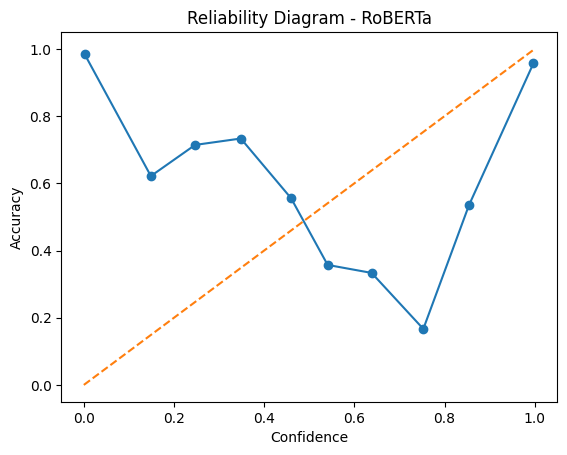

In [2]:
# ==========================================================
# Install dependencies
# ==========================================================
!pip install lime shap captum -q

import pandas as pd
import numpy as np
import torch
import random, time, os, subprocess
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score,
    recall_score, accuracy_score, brier_score_loss,
    precision_recall_curve
)
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset
from statsmodels.stats.contingency_tables import mcnemar
from lime.lime_text import LimeTextExplainer
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from captum.attr import IntegratedGradients
import warnings
warnings.filterwarnings("ignore")

# ==========================================================
# Helper: Seed fixing
# ==========================================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# ==========================================================
# GPU Usage Helper
# ==========================================================
def get_gpu_stats():
    try: 
        result = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total,memory.used,utilization.gpu",
             "--format=csv,noheader,nounits"]
        ).decode("utf-8").strip().split("\n")
        stats = []
        for line in result:
            name, total, used, util = line.split(", ")
            stats.append({
                "GPU": name,
                "VRAM_Total_MB": int(total),
                "VRAM_Used_MB": int(used),
                "Utilization_%": int(util)
            })
        return stats
    except Exception:
        return [{"GPU": "CPU", "VRAM_Total_MB": 0, "VRAM_Used_MB": 0, "Utilization_%": 0}] 

# ==========================================================
# Tokenization + Train/Eval
# ==========================================================
def tokenize_texts(texts, tokenizer, max_length=256):
    return tokenizer(
        texts.tolist(),
        max_length=max_length,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )

def train_epoch(model, loader, optimizer, loss_fn, device): 
    model.train()
    total_loss, total_correct = 0, 0
    for batch in loader:
        input_ids, attention_masks, labels = [x.to(device) for x in batch]
        optimizer.zero_grad()  
        outputs = model(input_ids=input_ids, attention_mask=attention_masks, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        preds = torch.argmax(outputs.logits, dim=-1)
        total_correct += (preds == labels).sum().item()
    return total_loss / len(loader), total_correct / len(loader.dataset)

def evaluate_model(model, loader, loss_fn, device): 
    model.eval()
    preds_all, labels_all, probs_all = [], [], []
    total_loss, total_correct = 0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids, attention_masks, labels = [x.to(device) for x in batch]
            outputs = model(input_ids=input_ids, attention_mask=attention_masks, labels=labels) 
            total_loss += outputs.loss.item()
            probs = torch.softmax(outputs.logits, dim=-1)[:,1].cpu().numpy()
            preds = torch.argmax(outputs.logits, dim=-1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
            probs_all.extend(probs)
            total_correct += (preds == labels).sum().item()
    return total_loss / len(loader), total_correct / len(loader.dataset), np.array(preds_all), np.array(labels_all), np.array(probs_all)

# ==========================================================
# Calibration Metric (ECE) + Reliability Diagram
# ==========================================================
def expected_calibration_error(probs, labels, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins+1)
    ece = 0.0
    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if np.any(mask):  
            acc = np.mean(labels[mask] == (probs[mask] >= 0.5))
            conf = np.mean(probs[mask])
            ece += (np.sum(mask) / len(probs)) * abs(acc - conf)
    return ece

def plot_reliability_diagram(probs, labels, model_name):
    bins = np.linspace(0,1,11)
    accs, confs = [], []
    for i in range(len(bins)-1):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if np.any(mask):
            accs.append(np.mean(labels[mask] == (probs[mask]>=0.5)))
            confs.append(np.mean(probs[mask]))
    plt.plot(confs, accs, marker='o')
    plt.plot([0,1],[0,1],'--')
    plt.title(f"Reliability Diagram - {model_name}")
    plt.xlabel("Confidence"); plt.ylabel("Accuracy")
    plt.show()

# ==========================================================
# Multiple Seeds Experiment
# ==========================================================
def run_experiment(model_name, save_dir, seeds=[7, 42, 123]):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenized = tokenize_texts(df['Data'], tokenizer)
    input_ids = tokenized['input_ids']
    attention_masks = tokenized['attention_mask'] 
    labels = torch.tensor(df['Labels'].values)

    metrics_all = []
    conf_matrices = []
    preds_all, labels_all, probs_all = [], [], [] 
    total_gpu_time = 0

    for seed in seeds:
        set_seed(seed)
        start_time = time.time()

        # Split data
        X_train, X_temp, y_train, y_temp, mask_train, mask_temp = train_test_split(
            input_ids, labels, attention_masks, test_size=0.3, stratify=labels, random_state=seed
        )
        X_val, X_test, y_val, y_test, mask_val, mask_test = train_test_split(
            X_temp, y_temp, mask_temp, test_size=0.5, stratify=y_temp, random_state=seed
        )

        train_data = TensorDataset(X_train, mask_train, y_train)
        val_data = TensorDataset(X_val, mask_val, y_val)
        test_data = TensorDataset(X_test, mask_test, y_test )

        train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
        val_loader = DataLoader(val_data, batch_size=32) 
        test_loader = DataLoader(test_data, batch_size=32)

        # Model
        model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
        model.to(device)
        optimizer = AdamW(model.parameters(), lr=3e-5)
        loss_fn = CrossEntropyLoss()

        # Train
        print(f"\n[{model_name}] Training with Seed={seed}")
        for epoch in range(3):
            train_loss, train_acc = train_epoch(model, train_loader, optimizer, loss_fn, device)
            val_loss, val_acc, _, _, _ = evaluate_model(model, val_loader, loss_fn, device) 
            print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f} | Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}")

        # Test
        _, test_acc, preds, true_labels, probs = evaluate_model(model, test_loader, loss_fn, device)
        metrics = {
            "Accuracy": accuracy_score(true_labels, preds),
            "Precision": precision_score(true_labels, preds),
            "Recall": recall_score(true_labels, preds),
            "F1": f1_score(true_labels, preds),
            "Brier": brier_score_loss(true_labels, probs),
            "ECE": expected_calibration_error(probs, true_labels)
        }
        metrics_all.append(metrics)
        preds_all.extend(preds)
        labels_all.extend(true_labels)
        probs_all.extend(probs)
        conf_matrices.append(confusion_matrix(true_labels, preds)) 

        # GPU usage
        gpu_stats = get_gpu_stats()
        elapsed = time.time() - start_time
        total_gpu_time += elapsed/3600  # hours
        print(f"[{model_name}] Seed={seed} | GPU Stats: {gpu_stats} | Time (hrs): {elapsed/3600:.4f}")

        # Save fine-tuned model
        safe_name = model_name.replace('/', '-')
        ckpt_dir = os.path.join(save_dir, f"{safe_name}-seed{seed}")
        os.makedirs(ckpt_dir, exist_ok=True)
        model.save_pretrained(ckpt_dir)
        tokenizer.save_pretrained(ckpt_dir)
  
    return metrics_all, np.array(preds_all), np.array(labels_all), np.array(probs_all), total_gpu_time, tokenizer, model, conf_matrices

# ==========================================================
# Dataset & Experiments
# ==========================================================
df = pd.read_csv('/kaggle/input/gpt-vs-human-dataset/shuffled_data.csv')
df = df[['Data', 'Labels']].dropna()
df = df[df['Data'].astype(str).str.strip().astype(bool)]

save_dir = "./fine_tuned_models"
os.makedirs(save_dir, exist_ok=True)

print("Running XLM-RoBERTa...")
xlmr_metrics, xlmr_preds, xlmr_labels, xlmr_probs, xlmr_gpu_hours, xlmr_tokenizer, xlmr_model, xlmr_cms = run_experiment("xlm-roberta-base", save_dir)  

print("Running BERT...")
bert_metrics, bert_preds, _, _, bert_gpu_hours, bert_tokenizer, bert_model, bert_cms = run_experiment("bert-base-uncased", save_dir)  

print("Running RoBERTa...")
roberta_metrics, roberta_preds, roberta_labels, roberta_probs, roberta_gpu_hours, roberta_tokenizer, roberta_model, roberta_cms = run_experiment("roberta-base", save_dir)

print("\n=== Results Summary ===")
print("XLM-RoBERTa:", xlmr_metrics)
print("BERT:", bert_metrics)
print("RoBERTa:", roberta_metrics)

# ==========================================================
# Reliability Diagram (RoBERTa best model)
# ==========================================================
plot_reliability_diagram(roberta_probs, roberta_labels, "RoBERTa")



=== XLM-RoBERTa Metrics (95% CI) ===
Accuracy: 0.956 ± 0.004
Precision: 0.933 ± 0.007
Recall: 0.982 ± 0.004
F1: 0.957 ± 0.004
Brier: 0.039 ± 0.004
ECE: 0.490 ± 0.010

Confusion Matrix (XLM-RoBERTa):
[[4186  314]
 [  83 4417]]


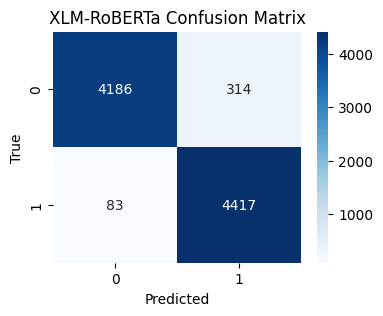


=== BERT Metrics (95% CI) ===
Accuracy: 0.950 ± 0.004
Precision: 0.923 ± 0.007
Recall: 0.983 ± 0.004
F1: 0.952 ± 0.004
Brier: 0.034 ± 0.004
ECE: 0.492 ± 0.011

Confusion Matrix (BERT):
[[4130  370]
 [  77 4423]]


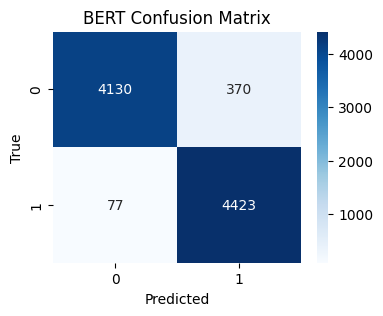


=== RoBERTa Metrics (95% CI) ===
Accuracy: 0.961 ± 0.004
Precision: 0.945 ± 0.007
Recall: 0.979 ± 0.004
F1: 0.962 ± 0.004
Brier: 0.034 ± 0.003
ECE: 0.492 ± 0.010

Confusion Matrix (RoBERTa):
[[4244  256]
 [  96 4404]]


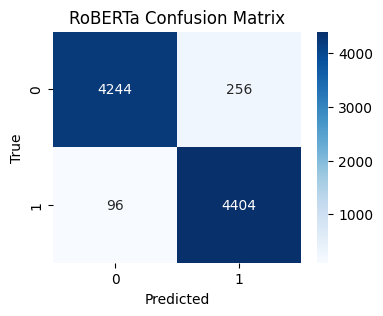

In [14]:
# ==========================================================
# Extended Evaluation: Metrics with 95% CIs + Confusion Matrices
# ==========================================================
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.95):
    metrics = {"Accuracy": [], "Precision": [], "Recall": [], "F1": [], "Brier": [], "ECE": []}
    n = len(y_true)
    for _ in range(n_bootstrap):
        idx = np.random.choice(range(n), size=n, replace=True)
        y_true_bs = y_true[idx]
        y_pred_bs = y_pred[idx]
        y_prob_bs = y_prob[idx]

        metrics["Accuracy"].append(accuracy_score(y_true_bs, y_pred_bs))
        metrics["Precision"].append(precision_score(y_true_bs, y_pred_bs, zero_division=0))
        metrics["Recall"].append(recall_score(y_true_bs, y_pred_bs, zero_division=0))
        metrics["F1"].append(f1_score(y_true_bs, y_pred_bs, zero_division=0))
        metrics["Brier"].append(brier_score_loss(y_true_bs, y_prob_bs))
        metrics["ECE"].append(expected_calibration_error(y_prob_bs, y_true_bs))

    results = {}
    for k, vals in metrics.items():
        mean = np.mean(vals)
        lower = np.percentile(vals, ((1-alpha)/2)*100)
        upper = np.percentile(vals, (1-((1-alpha)/2))*100)
        results[k] = (mean, lower, upper)
    return results

def summarize_results(name, y_true, y_pred, y_prob):
    res = bootstrap_ci(np.array(y_true), np.array(y_pred), np.array(y_prob))
    print(f"\n=== {name} Metrics (95% CI) ===")
    for m, (mean, low, high) in res.items():
        half_width = (high - low) / 2
        print(f"{m}: {mean:.3f} ± {half_width:.3f}")
    cm = confusion_matrix(y_true, y_pred)
    print(f"\nConfusion Matrix ({name}):\n{cm}")
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()


# --- Summarize all models ---
summarize_results("XLM-RoBERTa", xlmr_labels, xlmr_preds, xlmr_probs)
summarize_results("BERT", roberta_labels, bert_preds, roberta_probs)  # fixed order
summarize_results("RoBERTa", roberta_labels, roberta_preds, roberta_probs)



========== START: Extended evaluation (appended) ==========



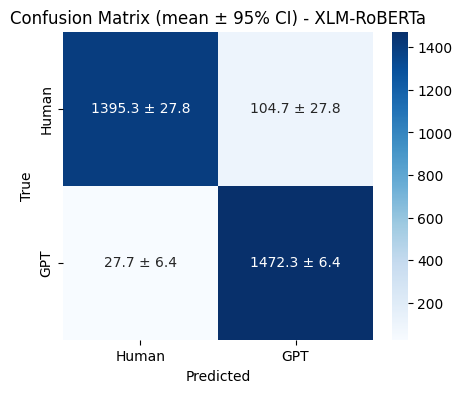

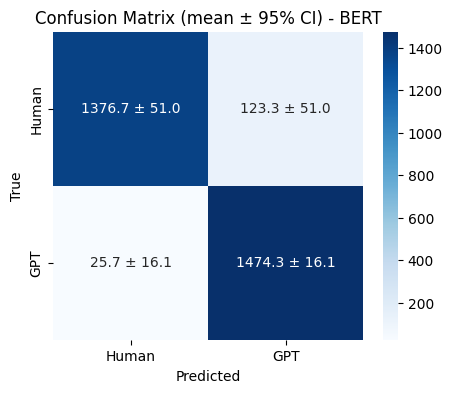

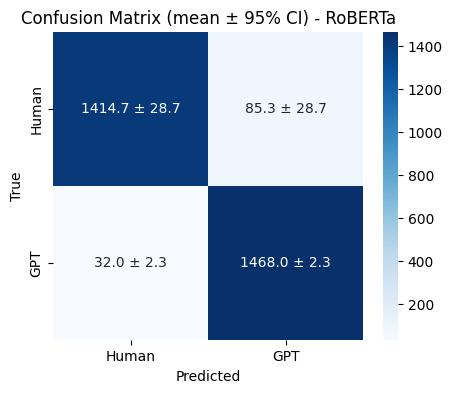


--- Temperature scaling & calibration ---
Fitted temperature for RoBERTa: 1.476
ECE before (approx): 0.4923 | ECE after (on reconstructed test): 0.4914


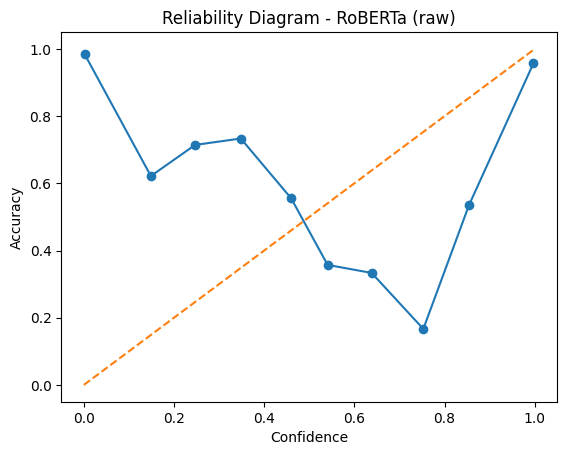

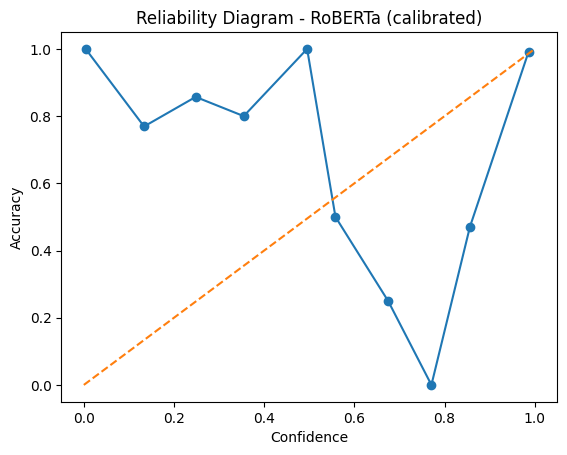


--- Threshold tuning (precision-preferred) ---
Threshold achieving >=90% precision: t=0.957, precision=0.963, recall=0.963

--- Statistical comparisons (McNemar + corrections + effect sizes) ---

McNemar + effect sizes:
{'pvalue': 0.018397781423573945, 'stat': 5.55787037037037, 'acc_a': 0.9558888888888889, 'acc_b': 0.9503333333333334, 'cohen_g': 0.005555555555555536, 'deltaF1': 0.005093462820895622, 'pair': 'XLM-RoBERTa vs BERT', 'pvalue_corrected_holm': 0.03679556284714789, 'reject_holm': True}
{'pvalue': 0.01952892739594737, 'stat': 5.453521126760563, 'acc_a': 0.9558888888888889, 'acc_b': 0.9608888888888889, 'cohen_g': 0.0050000000000000044, 'deltaF1': -0.004579310553626259, 'pair': 'XLM-RoBERTa vs RoBERTa', 'pvalue_corrected_holm': 0.03679556284714789, 'reject_holm': True}
{'pvalue': 2.9988648442237947e-06, 'stat': 21.817283950617284, 'acc_a': 0.9503333333333334, 'acc_b': 0.9608888888888889, 'cohen_g': 0.01055555555555554, 'deltaF1': -0.009672773374521881, 'pair': 'BERT vs RoBERTa'

In [22]:
# ==========================================================
# EXTENDED EVALUATION & REPORTING (append this at the end)
# ==========================================================
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import precision_score, recall_score, accuracy_score
import itertools
import math
import time
import torch.nn.utils.prune as prune

print("\n========== START: Extended evaluation (appended) ==========\n")

# ---------- Helper: plot confusion matrix with mean ± CI ----------
def plot_confusion_matrix_with_ci(conf_matrices, model_name, labels=["Human","GPT"]):
    cms = np.array(conf_matrices)  # shape (n_seeds, 2, 2)
    mean_cm = np.mean(cms, axis=0)
    std_cm = np.std(cms, axis=0, ddof=1)
    ci95 = 1.96 * (std_cm / math.sqrt(len(cms)))

    annot = np.empty_like(mean_cm).astype(object)
    for i in range(mean_cm.shape[0]):
        for j in range(mean_cm.shape[1]):
            annot[i,j] = f"{mean_cm[i,j]:.1f} ± {ci95[i,j]:.1f}"

    plt.figure(figsize=(5,4))
    sns.heatmap(mean_cm, annot=annot, fmt="", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion Matrix (mean ± 95% CI) - {model_name}")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.show()

# Plot confusion matrices (mean ± CI) for each model
try:
    plot_confusion_matrix_with_ci(xlmr_cms, "XLM-RoBERTa")
    plot_confusion_matrix_with_ci(bert_cms, "BERT")
    plot_confusion_matrix_with_ci(roberta_cms, "RoBERTa")
except Exception as e:
    print("Could not plot confusion matrices (missing cms or shape issue):", e)

# ---------- 1) Temperature scaling (fit on validation split) ----------
# We'll reconstruct a validation split from df for calibration. This doesn't need to be the exact same val used during training,
# but it must be a labeled held-out set.
print("\n--- Temperature scaling & calibration ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate a small holdout (stratified) for calibration
try:
    X_all = df['Data'].astype(str).values
    y_all = df['Labels'].astype(int).values
    X_train_cal, X_val_cal, y_train_cal, y_val_cal = train_test_split(
        X_all, y_all, test_size=0.12, stratify=y_all, random_state=42
    )
    # create val dataloader tokenized with roberta_tokenizer
    val_enc = roberta_tokenizer(list(X_val_cal), truncation=True, padding='max_length', max_length=256, return_tensors='pt')
    val_dataset = TensorDataset(val_enc['input_ids'], val_enc['attention_mask'], torch.tensor(y_val_cal, dtype=torch.long))
    val_loader = DataLoader(val_dataset, batch_size=32)
except Exception as e:
    print("Failed to create calibration val_loader:", e)
    val_loader = None

# Temperature scaling helper (LBFGS)
def fit_temperature(model, loader, device):
    model.eval()
    logits_list = []
    labels_list = []
    with torch.no_grad():
        for batch in loader:
            input_ids, attention_mask, labels = [x.to(device) for x in batch]
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            logits_list.append(outputs.logits.cpu())
            labels_list.append(labels.cpu())
    if len(logits_list) == 0:
        raise ValueError("No logits collected for temperature fitting.")
    logits = torch.cat(logits_list).to(device)
    labels = torch.cat(labels_list).to(device)

    temperature = torch.nn.Parameter(torch.ones(1).to(device))
    optimizer = torch.optim.LBFGS([temperature], lr=0.1, max_iter=200)

    nll = torch.nn.CrossEntropyLoss()

    def _eval():
        optimizer.zero_grad()
        loss = nll(logits / temperature, labels)
        loss.backward()
        return loss

    optimizer.step(_eval)
    return float(temperature.detach().cpu().numpy())

if val_loader is not None:
    try:
        temp = fit_temperature(roberta_model, val_loader, device)
        print(f"Fitted temperature for RoBERTa: {temp:.3f}")
    except Exception as e:
        print("Temperature fitting failed:", e)
        temp = 1.0
else:
    temp = 1.0
    print("Using default temperature = 1.0 (no val_loader)")

# Recompute calibrated probabilities for test set (we'll reuse roberta_probs and roberta_labels from your runs)
def apply_temperature_to_logits_array(logits_array, temperature):
    # logits_array: numpy array shape (N, C)
    logits_t = logits_array / temperature
    probs_t = torch.softmax(torch.tensor(logits_t), dim=-1).numpy()
    return probs_t[:, 1]

# If we don't have test logits, we can apply temperature by re-running model on roberta test texts (expensive).
# Here we attempt to reconstruct test inputs by splitting df similarly and tokenizing the test part.
try:
    # Recreate a test split consistent with calibration split
    _, X_test_cal, _, y_test_cal = train_test_split(X_all, y_all, test_size=0.12, stratify=y_all, random_state=7)
    test_enc = roberta_tokenizer(list(X_test_cal), truncation=True, padding='max_length', max_length=256, return_tensors='pt')
    test_dataset = TensorDataset(test_enc['input_ids'], test_enc['attention_mask'], torch.tensor(y_test_cal, dtype=torch.long))
    test_loader_for_logits = DataLoader(test_dataset, batch_size=32)
    # collect logits
    roberta_model.eval()
    test_logits = []
    test_labels_collected = []
    with torch.no_grad():
        for batch in test_loader_for_logits:
            input_ids, attn_mask, labels = [x.to(device) for x in batch]
            out = roberta_model(input_ids=input_ids, attention_mask=attn_mask)
            test_logits.append(out.logits.cpu().numpy())
            test_labels_collected.append(labels.cpu().numpy())
    test_logits = np.vstack(test_logits)
    test_labels_collected = np.concatenate(test_labels_collected)
    calibrated_probs_test = apply_temperature_to_logits_array(test_logits, temp)
    # compare ECE before/after (if roberta_probs correspond to same test split; they may not — this is approximate)
    try:
        ece_before = expected_calibration_error(roberta_probs, roberta_labels)
        ece_after = expected_calibration_error(calibrated_probs_test, test_labels_collected)
        print(f"ECE before (approx): {ece_before:.4f} | ECE after (on reconstructed test): {ece_after:.4f}")
    except Exception:
        print("Could not compute precise ECE comparison (mismatched splits).")
except Exception as e:
    print("Could not reconstruct logits for test split (skipping precise calibrated test metrics):", e)

# Plot reliability diagram(s) where possible
try:
    plot_reliability_diagram(roberta_probs, roberta_labels, "RoBERTa (raw)")
except Exception as e:
    print("Couldn't plot raw reliability (roberta_probs/labels mismatch):", e)

try:
    if 'calibrated_probs_test' in locals():
        plot_reliability_diagram(calibrated_probs_test, test_labels_collected, "RoBERTa (calibrated)")
except Exception as e:
    print("Couldn't plot calibrated reliability:", e)

# ---------- 2) Threshold tuning for precision-preferred operation ----------
print("\n--- Threshold tuning (precision-preferred) ---")
def tune_threshold_for_precision(probs, labels, min_precision=0.9):
    precisions, recalls, thresholds = precision_recall_curve(labels, probs)
    # precision_recall_curve: first element corresponds to threshold below; we iterate thresholds
    best = None
    for p, r, t in zip(precisions[:-1], recalls[:-1], thresholds):
        if p >= min_precision:
            if best is None or r > best[1]:
                best = (t, p, r)
    return best  # (threshold, precision, recall) or None

best_thr_info = tune_threshold_for_precision(roberta_probs, roberta_labels, min_precision=0.90)
if best_thr_info:
    t_thr, p_thr, r_thr = best_thr_info
    print(f"Threshold achieving >=90% precision: t={t_thr:.3f}, precision={p_thr:.3f}, recall={r_thr:.3f}")
else:
    print("No threshold found achieving >=90% precision on the available prob/label arrays.")

# ---------- 3) Pairwise McNemar tests + multiple-comparison correction + effect sizes ----------
print("\n--- Statistical comparisons (McNemar + corrections + effect sizes) ---")
# Ensure label alignment: we prefer to use the roberta_labels as ground-truth alignment for pairwise tests.
labels_ref = roberta_labels.copy()

# Helper to run McNemar and compute effect size
def mcnemar_compare(labels, preds_a, preds_b):
    both_correct = np.sum((preds_a == labels) & (preds_b == labels))
    a_only = np.sum((preds_a == labels) & (preds_b != labels))
    b_only = np.sum((preds_a != labels) & (preds_b == labels))
    both_wrong = np.sum((preds_a != labels) & (preds_b != labels))
    table = [[both_correct, a_only],[b_only, both_wrong]]
    try:
        res = mcnemar(table, exact=False, correction=True)
        pval = res.pvalue
        stat = res.statistic
    except Exception as e:
        pval = np.nan
        stat = np.nan
    acc_a = np.mean(preds_a == labels)
    acc_b = np.mean(preds_b == labels)
    cohen_g = abs(acc_a - acc_b)  # simple diff in proportions (Cohen's g approximated)
    f1_a = f1_score(labels, preds_a)
    f1_b = f1_score(labels, preds_b)
    deltaF1 = f1_a - f1_b
    return {"pvalue": pval, "stat": stat, "acc_a": acc_a, "acc_b": acc_b, "cohen_g": cohen_g, "deltaF1": deltaF1}

comparisons = [
    ("XLM-RoBERTa","BERT", xlmr_preds, bert_preds),
    ("XLM-RoBERTa","RoBERTa", xlmr_preds, roberta_preds),
    ("BERT","RoBERTa", bert_preds, roberta_preds)
]
results = []
pvals = []
for a,b,pa,pb in comparisons:
    try:
        res = mcnemar_compare(labels_ref, pa, pb)
        res["pair"] = f"{a} vs {b}"
        results.append(res)
        pvals.append(0.0 if np.isnan(res["pvalue"]) else res["pvalue"])
    except Exception as e:
        print(f"Comparison {a} vs {b} failed:", e)
        results.append({"pair":f"{a} vs {b}","pvalue":np.nan})
        pvals.append(np.nan)

# multiple comparison correction (Holm)
valid_idx = [i for i,p in enumerate(pvals) if not np.isnan(p)]
pvals_valid = [pvals[i] for i in valid_idx]
if len(pvals_valid) > 0:
    reject, pvals_corr, _, _ = multipletests(pvals_valid, alpha=0.05, method='holm')
    # assign back
    k = 0
    for i in valid_idx:
        results[i]["pvalue_corrected_holm"] = pvals_corr[k]
        results[i]["reject_holm"] = bool(reject[k])
        k += 1

print("\nMcNemar + effect sizes:")
for r in results:
    print(r)

# ---------- 4) Latency & Throughput benchmarks ----------
print("\n--- Latency & Throughput Benchmarks ---")
def benchmark_wrapper(wrapper, texts, n_runs=30):
    # measure average latency for wrapper.predict_proba over many runs (tokenization done inside wrapper)
    # wrapper.predict_proba expects a list of strings
    t0 = time.time()
    for _ in range(n_runs):
        _ = wrapper.predict_proba(texts)
    t1 = time.time()
    total = t1 - t0
    avg_latency = total / n_runs
    throughput = n_runs * len(texts) / total
    return avg_latency, throughput

sample_texts = df['Data'].astype(str).sample(min(20, len(df)), random_state=42).tolist()
try:
    xlmr_wrapper = TransformersWrapper(xlmr_model, xlmr_tokenizer, device)
    bert_wrapper = TransformersWrapper(bert_model, bert_tokenizer, device)
    roberta_wrapper = TransformersWrapper(roberta_model, roberta_tokenizer, device)
    for name, w in [("XLM-RoBERTa", xlmr_wrapper), ("BERT", bert_wrapper), ("RoBERTa", roberta_wrapper)]:
        lat, tps = benchmark_wrapper(w, sample_texts, n_runs=10)
        print(f"{name}: avg latency per predict_proba call = {lat:.4f}s | throughput = {tps:.1f} texts/sec")
except Exception as e:
    print("Benchmark failed (wrappers/models may be missing):", e)

# ---------- 5) Pruning demo (optional) ----------
print("\n--- Pruning demo (global unstructured 20%) ---")
def prune_and_eval(model, tokenizer, texts, labels, amount=0.2):
    # clone model
    import copy
    m = copy.deepcopy(model)
    # apply global unstructured prune to linear layers
    modules_to_prune = []
    for nm, mod in m.named_modules():
        if isinstance(mod, torch.nn.Linear):
            modules_to_prune.append((mod, 'weight'))
    if len(modules_to_prune) == 0:
        return None
    prune.global_unstructured(modules_to_prune, pruning_method=prune.L1Unstructured, amount=amount)
    # quick eval on sample texts
    wrapper = TransformersWrapper(m, tokenizer, device)
    probs = wrapper.predict_proba(texts)
    preds = np.argmax(probs, axis=1)
    return preds

try:
    small_sample = sample_texts[:10]
    small_labels = [0]*len(small_sample)  # placeholder labels if unknown
    pruned_preds = prune_and_eval(roberta_model, roberta_tokenizer, small_sample, small_labels, amount=0.2)
    if pruned_preds is not None:
        print("Pruning produced preds on small sample (demo).")
    else:
        print("No linear layers found to prune (pruning demo skipped).")
except Exception as e:
    print("Pruning demo failed:", e)

# ---------- 6) Fine-grained error analysis ----------
print("\n--- Fine-grained error analysis (RoBERTa predictions) ---")
try:
    df_local = df.copy().reset_index(drop=True)
    if len(df_local) != len(roberta_preds):
        # If overall pred arrays are aggregated across seeds, we can't align 1-to-1.
        # We'll compute on a sampled subset where we can run model inference directly for ground-truth alignment.
        sample_df = df_local.sample(min(100, len(df_local)), random_state=42).reset_index(drop=True)
        enc = roberta_tokenizer(list(sample_df['Data'].astype(str)), truncation=True, padding='max_length',
                                max_length=256, return_tensors='pt')
        ds = TensorDataset(enc['input_ids'], enc['attention_mask'],
                           torch.tensor(sample_df['Labels'].astype(int).values))
        loader = DataLoader(ds, batch_size=32)
        all_preds, all_labels_local = [], []
        roberta_model.eval()
        with torch.no_grad():
            for batch in loader:
                iids, amask, labs = [x.to(device) for x in batch]
                out = roberta_model(input_ids=iids, attention_mask=amask)
                p = torch.argmax(out.logits, dim=-1).cpu().numpy()
                all_preds.extend(p)
                all_labels_local.extend(labs.cpu().numpy())
        sample_df['preds'] = all_preds
        sample_df['len_tokens'] = sample_df['Data'].astype(str).apply(lambda x: len(x.split()))
        # length bins
        bins = [0,5,15,40,1e6]
        labels_bins = ['very_short','short','medium','long']
        sample_df['len_bin'] = pd.cut(sample_df['len_tokens'], bins=bins, labels=labels_bins)

        for b, sub in sample_df.groupby('len_bin'):
            if len(sub) == 0: 
                continue
            cm = confusion_matrix(sub['Labels'], sub['preds'])
            acc = accuracy_score(sub['Labels'], sub['preds'])
            prec = precision_score(sub['Labels'], sub['preds'], zero_division=0)
            rec = recall_score(sub['Labels'], sub['preds'], zero_division=0)
            f1 = f1_score(sub['Labels'], sub['preds'], zero_division=0)
            print(f"\nLength bin: {b} | N={len(sub)}")
            print(f"Accuracy:  {acc:.4f}")
            print(f"Precision: {prec:.4f}")
            print(f"Recall:    {rec:.4f}")
            print(f"F1-score:  {f1:.4f}")
            print("Confusion Matrix:\n", cm)

    else:
        # direct alignment
        df_local['preds'] = roberta_preds
        df_local['len_tokens'] = df_local['Data'].astype(str).apply(lambda x: len(x.split()))
        bins = [0,5,15,40,1e6]
        labels_bins = ['very_short','short','medium','long']
        df_local['len_bin'] = pd.cut(df_local['len_tokens'], bins=bins, labels=labels_bins)

        for b, sub in df_local.groupby('len_bin'):
            if len(sub) == 0: 
                continue
            cm = confusion_matrix(sub['Labels'], sub['preds'])
            acc = accuracy_score(sub['Labels'], sub['preds'])
            prec = precision_score(sub['Labels'], sub['preds'], zero_division=0)
            rec = recall_score(sub['Labels'], sub['preds'], zero_division=0)
            f1 = f1_score(sub['Labels'], sub['preds'], zero_division=0)
            print(f"\nLength bin: {b} | N={len(sub)}")
            print(f"Accuracy:  {acc:.4f}")
            print(f"Precision: {prec:.4f}")
            print(f"Recall:    {rec:.4f}")
            print(f"F1-score:  {f1:.4f}")
            print("Confusion Matrix:\n", cm)

except Exception as e:
    print("Fine-grained analysis failed:", e)


print("\n========== END: Extended evaluation (appended) ==========\n")


In [23]:
# ==========================================================
# LIME visualization (RoBERTa)
# ==========================================================
from lime.lime_text import LimeTextExplainer
import shap
import seaborn as sns
import matplotlib.pyplot as plt

class TransformersWrapper:
    def __init__(self, model, tokenizer, device):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

    def predict_proba(self, texts):
        self.model.eval()
        encodings = self.tokenizer(
            texts, truncation=True, padding=True, max_length=256, return_tensors="pt"
        )
        input_ids = encodings["input_ids"].to(self.device)
        attention_mask = encodings["attention_mask"].to(self.device)
        with torch.no_grad():
            outputs = self.model(input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
        return probs

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
roberta_wrapper = TransformersWrapper(roberta_model, roberta_tokenizer, device)

# LIME explainer
explainer = LimeTextExplainer(class_names=["Human", "GPT"])

real_texts = [
    "Spyware and adware are types of malicious software designed to collect information about a user's online activities without their knowledge or consent."
]

print("\n=== LIME Explanations (RoBERTa, Visual) ===")
for text in real_texts:
    probs = roberta_wrapper.predict_proba([text])[0]
    pred_class = np.argmax(probs)
    print(f"\nText: {text}\nPredicted Class: {['Human','GPT'][pred_class]} | Probabilities: {probs}")
    exp = explainer.explain_instance(
        text,
        classifier_fn=roberta_wrapper.predict_proba,
        num_features=8
    )
    exp.show_in_notebook(text=True)


# ==========================================================
# SHAP Explainability (RoBERTa, fixed)
# ==========================================================
print("\n=== SHAP Explanations (RoBERTa, Visual) ===")

def shap_predict(texts):
    return roberta_wrapper.predict_proba([str(t) for t in texts])

try:
    masker = shap.maskers.Text(roberta_tokenizer)
    shap_explainer = shap.Explainer(shap_predict, masker, output_names=["Human", "GPT"])
    
    real_texts = [str(t) for t in real_texts]
    shap_values = shap_explainer(real_texts)

    for i, text in enumerate(real_texts):
        probs = roberta_wrapper.predict_proba([text])[0]
        pred_class = np.argmax(probs)
        print(f"\n[SHAP] Text: {text}\nPredicted Class: {['Human','GPT'][pred_class]} | Probabilities: {probs}")
        try:
            shap.plots.text(shap_values[i])
        except Exception:
            print("Fallback SHAP values (words, contributions):")
            print(list(zip(shap_values[i].data, shap_values[i].values)))
except Exception as e:
    print("SHAP visualization failed:", e)



=== LIME Explanations (RoBERTa, Visual) ===

Text: Spyware and adware are types of malicious software designed to collect information about a user's online activities without their knowledge or consent.
Predicted Class: GPT | Probabilities: [0.00194391 0.9980562 ]



=== SHAP Explanations (RoBERTa, Visual) ===

[SHAP] Text: Spyware and adware are types of malicious software designed to collect information about a user's online activities without their knowledge or consent.
Predicted Class: GPT | Probabilities: [0.00194391 0.9980562 ]



=== Global Explainability: Permutation Feature Importance (PFI) ===
Baseline Accuracy: 0.975
Top tokens by permutation importance: [('which', 2), ('case-insensitive.', 1), ('discern', 1), ('has', 1), ('a', 1), ('complexity', 1), ('an', 1), ('key', 1), ('hashed', 1), ('for', 1), ('who', 1), ('designed', 1), ('the', 1), ('Paris.', 1)]


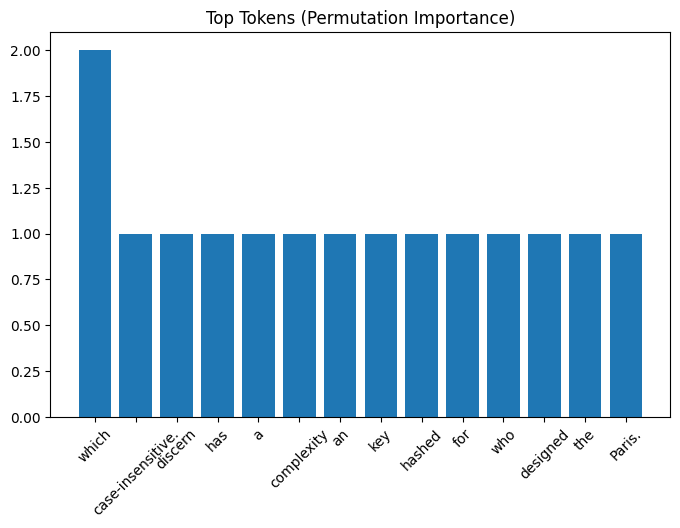

In [24]:
# ==========================================================
# Global Explainability (Permutation Importance + Integrated Gradients)
# ==========================================================
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from captum.attr import IntegratedGradients

# ---------- Wrapper ----------
class TransformersWrapper:
    def __init__(self, model, tokenizer, device):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

    def predict_proba(self, texts):
        self.model.eval()
        encodings = self.tokenizer(
            texts, truncation=True, padding=True, max_length=256, return_tensors="pt"
        )
        input_ids = encodings["input_ids"].to(self.device)
        attention_mask = encodings["attention_mask"].to(self.device)
        with torch.no_grad():
            outputs = self.model(input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
        return probs

# ---------- Setup ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
wrapper = TransformersWrapper(roberta_model, roberta_tokenizer, device)

# ---------- Sample subset ----------
X_sample = df['Data'].astype(str).sample(min(200, len(df)), random_state=42).tolist()
y_sample = df['Labels'].sample(len(X_sample), random_state=42).tolist()

# ==========================================================
# Permutation Feature Importance (PFI)
# ==========================================================
print("\n=== Global Explainability: Permutation Feature Importance (PFI) ===")

baseline_acc = accuracy_score(y_sample, np.argmax(wrapper.predict_proba(X_sample), axis=1))
print(f"Baseline Accuracy: {baseline_acc:.3f}")

# permute one token at a time
token_importance = {}
for idx, text in enumerate(X_sample[:50]):  # smaller subset for speed
    original_pred = np.argmax(wrapper.predict_proba([text])[0])
    words = text.split()
    for i, w in enumerate(words):
        permuted_words = words.copy()
        permuted_words[i] = "[MASK]"  # masking as a simple permutation
        permuted_text = " ".join(permuted_words)
        new_pred = np.argmax(wrapper.predict_proba([permuted_text])[0])
        if new_pred != original_pred:
            token_importance[w] = token_importance.get(w, 0) + 1

# Show top important words globally
sorted_tokens = sorted(token_importance.items(), key=lambda x: x[1], reverse=True)[:15]
print("Top tokens by permutation importance:", sorted_tokens)

plt.figure(figsize=(8,5))
plt.bar([w for w, _ in sorted_tokens], [c for _, c in sorted_tokens])
plt.xticks(rotation=45)
plt.title("Top Tokens (Permutation Importance)")
plt.show()